# Análise de Dados - Preços de Carros no Brasil

Este notebook tem como objetivo analisar a base de dados de preços de carros no Brasil, explorando distribuições e relações entre variáveis como marca, tipo de engrenagem, combustível e evolução de preços ao longo do tempo.

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuração visual
sns.set_theme(style="whitegrid")
%matplotlib inline

# 1. Carga e Padronização
df = pd.read_csv('precos_carros_brasil.csv')

# Padronizar nomes das colunas
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Definindo a coluna de preço correta baseada no seu print
col_preco = 'avg_price_brl'

# Garantir que o preço seja numérico (remover R$ ou símbolos se houver, caso contrário apenas garante float)
if df[col_preco].dtype == 'object':
    df[col_preco] = df[col_preco].str.replace('R$', '').str.replace('.', '').str.replace(',', '.').astype(float)

print("Coluna de preço definida como:", col_preco)

Coluna de preço definida como: avg_price_brl


# a. Distribuição da quantidade de carros por marca 

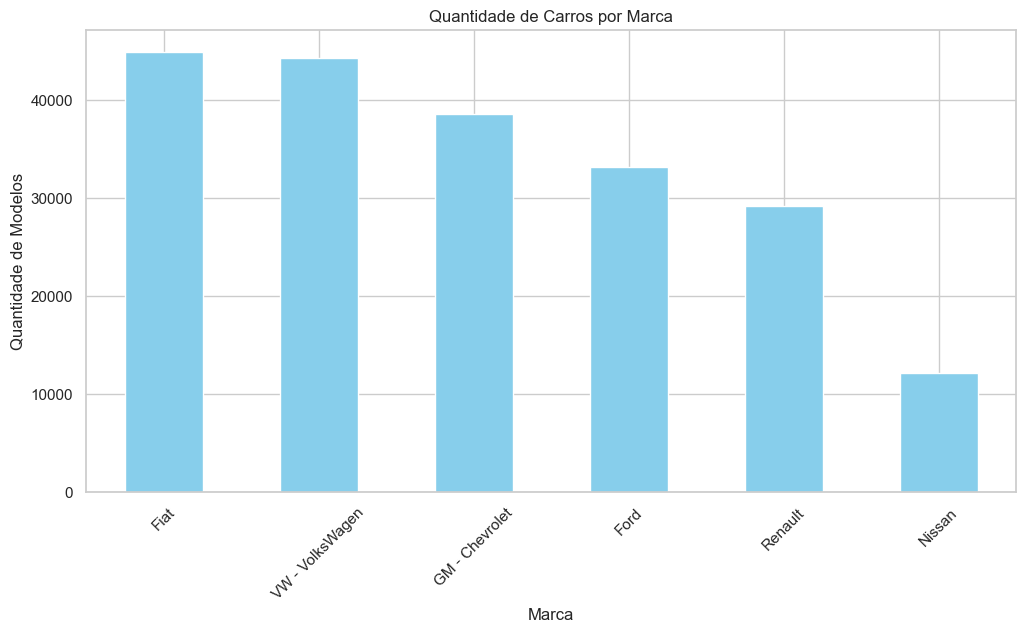

In [19]:
plt.figure(figsize=(12, 6))
df['brand'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Quantidade de Carros por Marca')
plt.xlabel('Marca')
plt.ylabel('Quantidade de Modelos')
plt.xticks(rotation=45)
plt.show()

# b. Distribuição da quantidade de carros por tipo de engrenagem

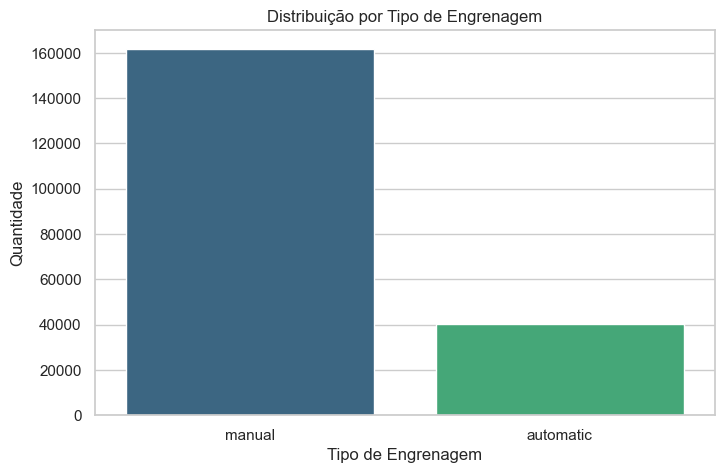

In [20]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='gear', palette='viridis')
plt.title('Distribuição por Tipo de Engrenagem')
plt.xlabel('Tipo de Engrenagem')
plt.ylabel('Quantidade')
plt.show()

# c. Evolução da média de preço em 2022

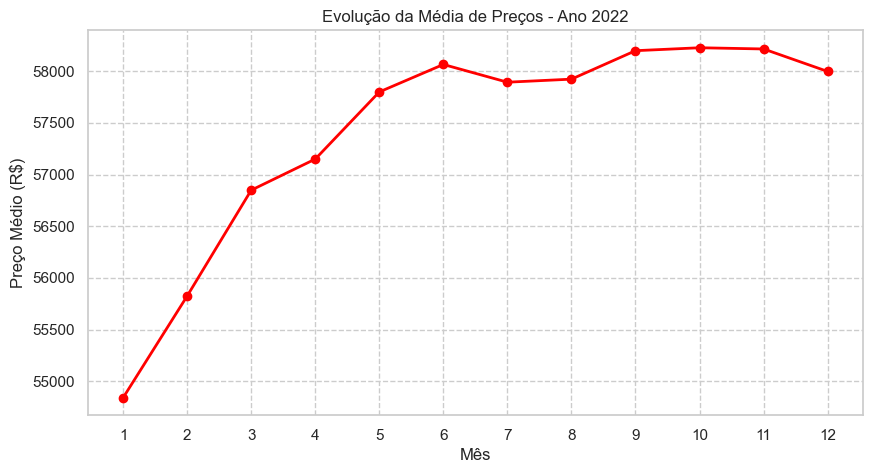

In [21]:
# Filtro para o ano de 2022
df_2022 = df[df['year_of_reference'] == 2022].copy()

# Mapeamento de meses para ordenação (considerando Português e Inglês)
meses_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12,
    'Janeiro': 1, 'Fevereiro': 2, 'Março': 3, 'Abril': 4, 'Maio': 5, 'Junho': 6,
    'Julho': 7, 'Agosto': 8, 'Setembro': 9, 'Outubro': 10, 'Novembro': 11, 'Dezembro': 12
}

df_2022['month_num'] = df_2022['month_of_reference'].map(meses_map)
df_2022 = df_2022.dropna(subset=['month_num'])

# Cálculo da média por mês
media_2022 = df_2022.groupby('month_num')[col_preco].mean()

plt.figure(figsize=(10, 5))
media_2022.plot(marker='o', color='red', linewidth=2)
plt.title('Evolução da Média de Preços - Ano 2022')
plt.xlabel('Mês')
plt.ylabel('Preço Médio (R$)')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--')
plt.show()

# d. Média de preço por marca e tipo de engrenagem

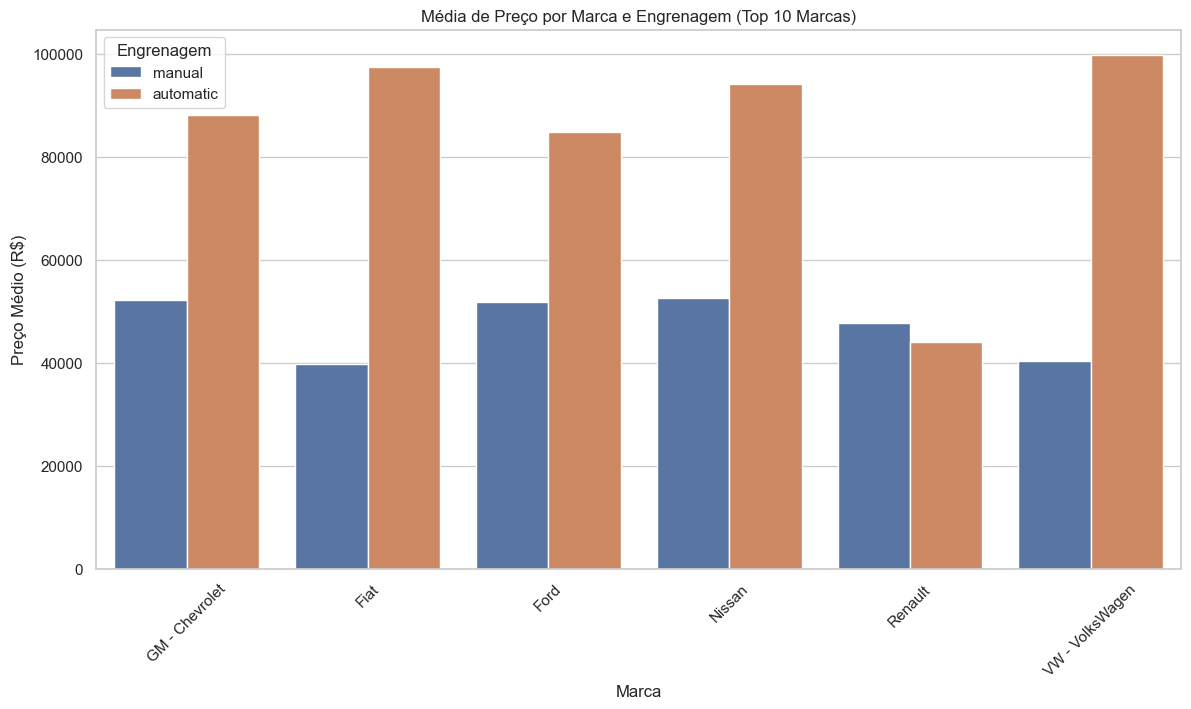

In [22]:
top_10_marcas = df['brand'].value_counts().nlargest(10).index
df_top = df[df['brand'].isin(top_10_marcas)]

plt.figure(figsize=(14, 7))
sns.barplot(data=df_top, x='brand', y=col_preco, hue='gear', ci=None)
plt.title('Média de Preço por Marca e Engrenagem (Top 10 Marcas)')
plt.xlabel('Marca')
plt.ylabel('Preço Médio (R$)')
plt.xticks(rotation=45)
plt.legend(title='Engrenagem')
plt.show()

# e. Explicação do item d

Os resultados mostram que modelos automáticos possuem, em média, preços significativamente maiores que os manuais em todas as marcas analisadas. Isso ocorre porque o câmbio automático costuma equipar versões de luxo, SUVs ou modelos com motorização mais potente e tecnologia embarcada.

# f. Média de preço por marca e tipo de combustível

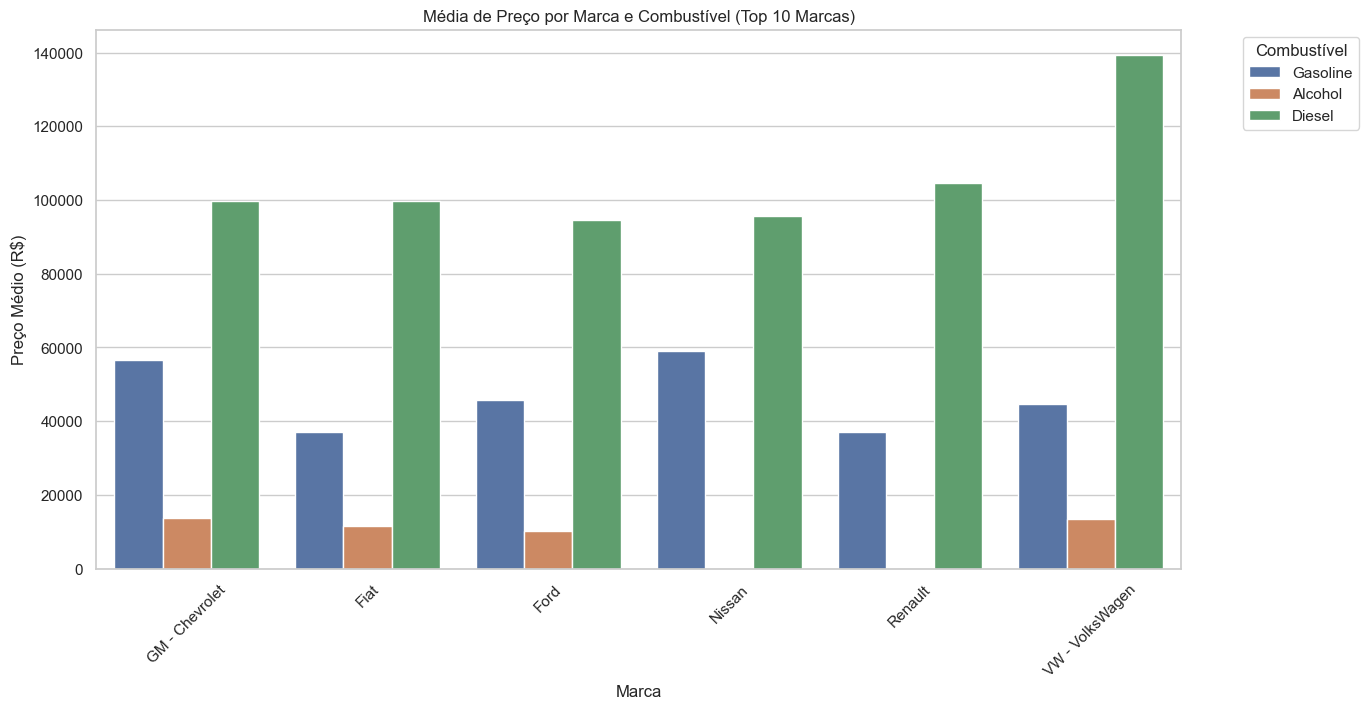

In [23]:
plt.figure(figsize=(14, 7))
sns.barplot(data=df_top, x='brand', y=col_preco, hue='fuel', ci=None)
plt.title('Média de Preço por Marca e Combustível (Top 10 Marcas)')
plt.xlabel('Marca')
plt.ylabel('Preço Médio (R$)')
plt.xticks(rotation=45)
plt.legend(title='Combustível', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# g. Explicação do item f

Veículos movidos a Diesel apresentam as médias de preço mais elevadas, frequentemente associadas a caminhonetes e SUVs de grande porte. Carros a Gasolina e Flex apresentam médias menores, pois compõem a maior parte da frota de veículos leves e populares no mercado brasileiro.